# ARTI 502 Assignment 2

Training and testing CNNs with CIFAR-10 using PyTorch

**Group 2 | Year 2026 Term 1**

| Member | Academic ID |
|---|---|
| Mohammed Jaarran | 2230000129 |
| Mohaiya Aldossary | 2230004579 |
| Sameer Almadani | 2230001818 |
| Omar Bodai | 2240040094 |
| Hussain Alabdurabalnabi | 2230004638 |

# Experiment 4 Improving CIFAR-10 accuracy

The original three experiments and their saved outputs are preserved below. To run only the new experiment, skip directly to **Experiment 4 implementation** at the end. Its cells are self-contained. In Google Colab, select a GPU runtime first. Locally, install PyTorch and torchvision for your hardware using https://pytorch.org/get-started/locally/ if needed.

The new experiment trains a six-convolution CNN from scratch for 40 epochs with batch normalization, dropout, AdamW weight decay, and a cosine learning-rate schedule. It uses random padded crops and horizontal flips rather than combining crop, rotation, color jitter, and noise. The completed 40-epoch run achieved 88.62% test accuracy with the validation-selected model from epoch 39. The final epoch itself achieved 88.55% test accuracy.

A stratified 45,000/5,000 training/validation split selects the checkpoint. Test loss and accuracy are also logged each epoch to satisfy Task 5, but are not used for checkpoint selection. Therefore its protocol differs from the original experiments, which trained on all 50,000 images and inspected the test set every epoch. The new experiment provides the required training-loss, test-loss, and test-accuracy curves, together with validation curves. The original Task 4 cell demonstrates all eight requested augmentation types; Experiment 4 tests a lighter augmentation combination. Avoid further tuning based on these test curves.

Training saves `history.json`, `results.json`, and `best_model.pt` in `experiment4_results`. GPU training uses mixed precision; fixed seeds improve repeatability but do not guarantee bit-for-bit reproducibility across devices.

## Original experiments

Execution record: Experiment 4 was run locally using the identical standalone implementation in `train_improved_cnn.py`. Its actual console log is embedded in the training cell, and the plotting cell was executed using the saved history. The original three experiments retain their supplied outputs.


In [ ]:
### Task-1 prep
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
print(torch.__version__)
import torchvision
print(torchvision.__version__)

2.14.0+cpu
0.29.0+cpu


In [2]:
###Task-1
import torch
import torchvision
import torchvision.transforms as transforms

DATA_PATH = './data_cifar'   # must be an empty directory

transform = transforms.ToTensor()

trainset = torchvision.datasets.CIFAR10(root=DATA_PATH, train=True,
                                        download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root=DATA_PATH, train=False,
                                       download=True, transform=transform)

print("Train samples:", len(trainset))   # 50000
print("Test samples:", len(testset))     # 10000
print("Classes:", trainset.classes)

100%|██████████| 170M/170M [20:22<00:00, 139kB/s]  
c:\Users\hp\miniconda3\envs\CONDASPACE\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Train samples: 50000
Test samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [ ]:
### Task-2.1 (Network)
import torch.nn as nn
import torch.nn.functional as F

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)    # 3x32x32  -> 32x32x32
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)   # 16x16    -> 64x16x16
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)  # 8x8      -> 128x8x8
        self.pool = nn.MaxPool2d(2, 2)                             # halves H and W
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # -> 32x16x16
        x = self.pool(F.relu(self.conv2(x)))   # -> 64x8x8
        x = self.pool(F.relu(self.conv3(x)))   # -> 128x4x4
        x = x.view(x.size(0), -1)              # -> 2048
        x = F.relu(self.fc1(x))                # -> 256
        return self.fc2(x)                     # -> 10 logits

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN().to(device)
print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


In [4]:
### Task-2.2 (Train and Test functions)
def train(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
    return total_loss / len(loader.dataset)

def test(model, loader, criterion):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
    return total_loss / len(loader.dataset), 100 * correct / len(loader.dataset)

Images tensor size: torch.Size([64, 3, 32, 32])
Labels tensor size: torch.Size([64])
Pixel range: 0.0 to 1.0


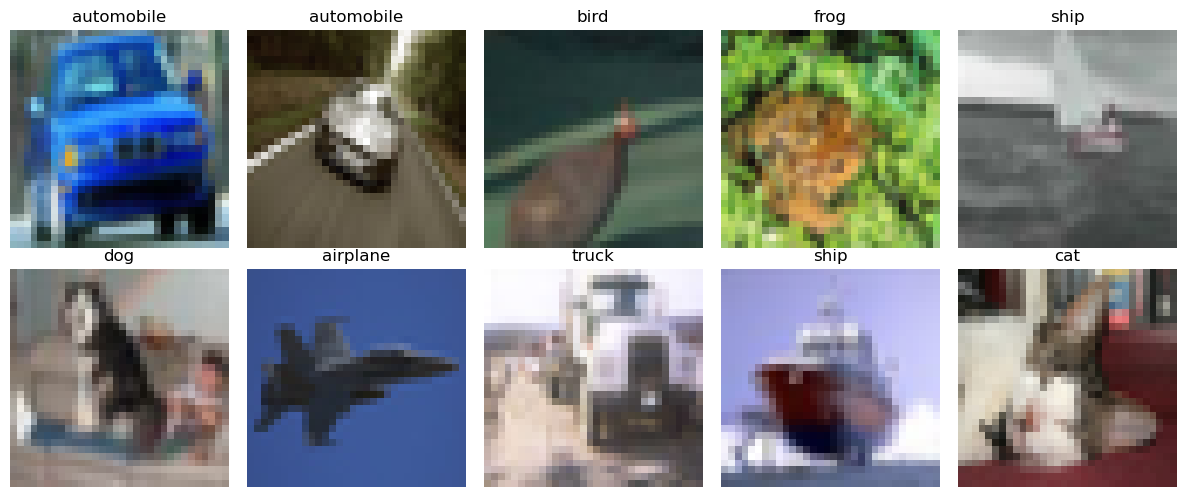

In [ ]:
### Task-3
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader

BATCH_SIZE = 64
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True)
testloader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False)

# 1. Images tensor size
images, labels = next(iter(trainloader))
print("Images tensor size:", images.shape)   # torch.Size([64, 3, 32, 32])
print("Labels tensor size:", labels.shape)   # torch.Size([64])
print("Pixel range:", images.min().item(), "to", images.max().item())

# 2. Visualization with matplotlib
classes = trainset.classes
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(np.transpose(images[i].numpy(), (1, 2, 0)))   # CxHxW -> HxWxC
    ax.set_title(classes[labels[i]])
    ax.axis("off")
plt.tight_layout()
plt.show()

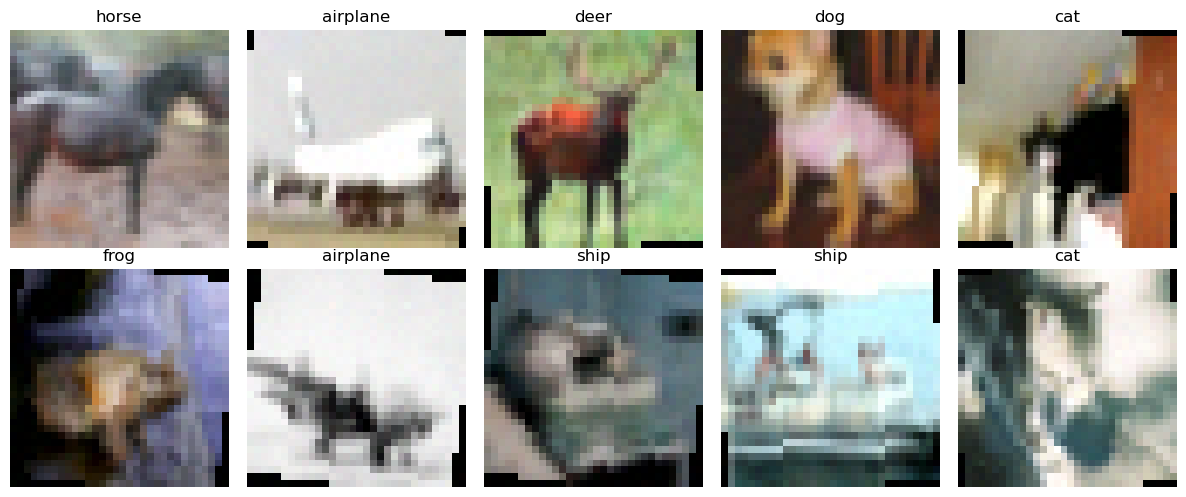

Train batch: torch.Size([64, 3, 32, 32])


In [7]:
### Task-4
import torch
import torchvision.transforms as transforms

MEAN = (0.4914, 0.4822, 0.4465)   # CIFAR-10 channel means
STD  = (0.2470, 0.2435, 0.2616)   # CIFAR-10 channel stds

class AddGaussianNoise:
    def __init__(self, std=0.03):
        self.std = std
    def __call__(self, tensor):
        return tensor + torch.randn_like(tensor) * self.std

train_transform = transforms.Compose([
    transforms.ToTensor(),                                      # PIL -> tensor (needed so ToPILImage gets a valid input)
    transforms.ToPILImage(),                                    # 1
    transforms.RandomHorizontalFlip(p=0.5),                     # 2
    transforms.RandomResizedCrop(32, scale=(0.8, 1.0)),         # 3
    transforms.ColorJitter(brightness=0.2, contrast=0.2,
                           saturation=0.2, hue=0.05),           # 4
    transforms.RandomRotation(10),                              # 5
    transforms.ToTensor(),                                      # 8
    transforms.Normalize(MEAN, STD),                            # 6
    AddGaussianNoise(0.03),                                     # 7
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Reload datasets with the new transforms (already downloaded, so no re-download)
trainset = torchvision.datasets.CIFAR10(root=DATA_PATH, train=True,
                                        download=False, transform=train_transform)
testset = torchvision.datasets.CIFAR10(root=DATA_PATH, train=False,
                                       download=False, transform=test_transform)

trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True)
testloader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False)

# Check: augmented samples (un-normalize for display)
images, labels = next(iter(trainloader))
mean = torch.tensor(MEAN).view(1, 3, 1, 1)
std = torch.tensor(STD).view(1, 3, 1, 1)
imgs = (images * std + mean).clamp(0, 1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(np.transpose(imgs[i].numpy(), (1, 2, 0)))
    ax.set_title(trainset.classes[labels[i]])
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Train batch:", images.shape)

Epoch  1/10 | train loss 1.5217 | test loss 1.2594 | test acc 54.18% | 110s
Epoch  2/10 | train loss 1.1532 | test loss 0.9859 | test acc 65.93% | 112s
Epoch  3/10 | train loss 0.9994 | test loss 0.8618 | test acc 70.08% | 114s
Epoch  4/10 | train loss 0.9148 | test loss 0.8327 | test acc 71.26% | 111s
Epoch  5/10 | train loss 0.8508 | test loss 0.7743 | test acc 73.62% | 118s
Epoch  6/10 | train loss 0.8009 | test loss 0.7436 | test acc 74.24% | 112s
Epoch  7/10 | train loss 0.7647 | test loss 0.6824 | test acc 76.81% | 111s
Epoch  8/10 | train loss 0.7299 | test loss 0.6768 | test acc 76.45% | 135s
Epoch  9/10 | train loss 0.7059 | test loss 0.6734 | test acc 76.92% | 140s
Epoch 10/10 | train loss 0.6843 | test loss 0.6864 | test acc 76.66% | 141s


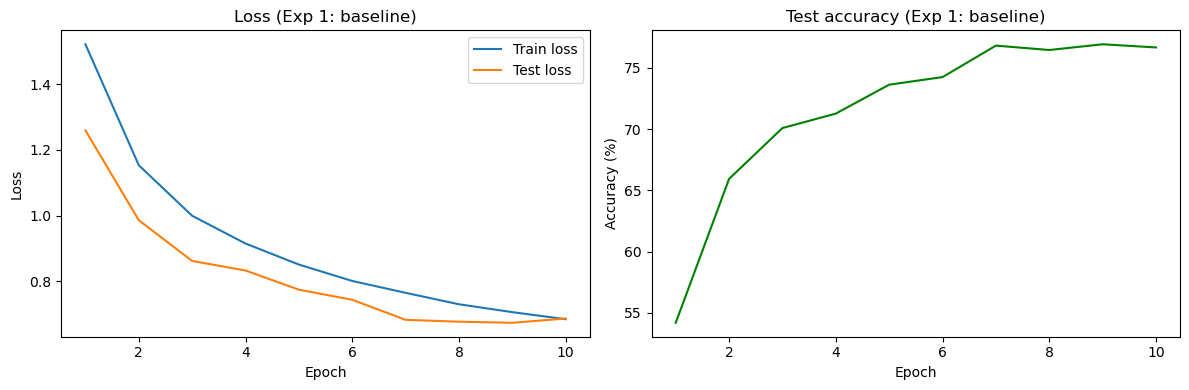

Final -> train loss 0.6843, test loss 0.6864, test acc 76.66%


In [ ]:
### Task-5.1 Exp 1: baseline
import time
import torch.optim as optim

def fit(model, epochs, lr, weight_decay=0.0, scheduler_step=None):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = (optim.lr_scheduler.StepLR(optimizer, step_size=scheduler_step, gamma=0.5)
                 if scheduler_step else None)
    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss = train(model, trainloader, optimizer, criterion)
        te_loss, te_acc = test(model, testloader, criterion)
        if scheduler:
            scheduler.step()
        hist["train_loss"].append(tr_loss)
        hist["test_loss"].append(te_loss)
        hist["test_acc"].append(te_acc)
        print(f"Epoch {epoch:2d}/{epochs} | train loss {tr_loss:.4f} | "
              f"test loss {te_loss:.4f} | test acc {te_acc:.2f}% | {time.time()-t0:.0f}s")
    return hist

def plot_history(hist, title=""):
    epochs = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(epochs, hist["train_loss"], label="Train loss")
    ax[0].plot(epochs, hist["test_loss"], label="Test loss")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend(); ax[0].set_title("Loss " + title)
    ax[1].plot(epochs, hist["test_acc"], color="green")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)"); ax[1].set_title("Test accuracy " + title)
    plt.tight_layout(); plt.show()

# Experiment 1: baseline
model = CNN().to(device)
hist1 = fit(model, epochs=10, lr=1e-3)
plot_history(hist1, "(Exp 1: baseline)")
print(f"Final -> train loss {hist1['train_loss'][-1]:.4f}, "
      f"test loss {hist1['test_loss'][-1]:.4f}, test acc {hist1['test_acc'][-1]:.2f}%")

Epoch  1/10 | train loss 1.4824 | test loss 1.0970 | test acc 60.87% | 119s
Epoch  2/10 | train loss 1.1803 | test loss 0.9587 | test acc 66.48% | 119s
Epoch  3/10 | train loss 1.0618 | test loss 0.8869 | test acc 69.14% | 117s
Epoch  4/10 | train loss 0.9820 | test loss 0.8111 | test acc 71.93% | 117s
Epoch  5/10 | train loss 0.9315 | test loss 0.7854 | test acc 72.98% | 118s
Epoch  6/10 | train loss 0.8818 | test loss 0.7271 | test acc 75.10% | 119s
Epoch  7/10 | train loss 0.8510 | test loss 0.7252 | test acc 75.17% | 118s
Epoch  8/10 | train loss 0.8198 | test loss 0.6933 | test acc 75.79% | 117s
Epoch  9/10 | train loss 0.7991 | test loss 0.6650 | test acc 77.16% | 118s
Epoch 10/10 | train loss 0.7704 | test loss 0.6624 | test acc 77.13% | 117s


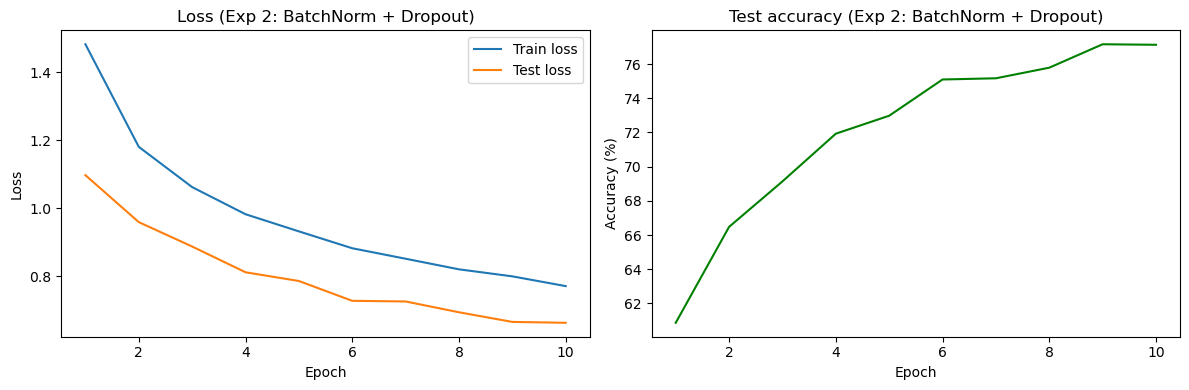

Final -> train loss 0.7704, test loss 0.6624, test acc 77.13%


In [10]:
### Task-5.2 Exp 2: BatchNorm + Dropout
class CNN2(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1);   self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1);  self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1); self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2, 2)
        self.drop = nn.Dropout(0.3)
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = x.view(x.size(0), -1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)

model2 = CNN2().to(device)
hist2 = fit(model2, epochs=10, lr=1e-3)
plot_history(hist2, "(Exp 2: BatchNorm + Dropout)")
print(f"Final -> train loss {hist2['train_loss'][-1]:.4f}, "
      f"test loss {hist2['test_loss'][-1]:.4f}, test acc {hist2['test_acc'][-1]:.2f}%")

Epoch  1/10 | train loss 1.6224 | test loss 1.1986 | test acc 56.71% | 114s
Epoch  2/10 | train loss 1.2897 | test loss 1.0398 | test acc 63.76% | 119s
Epoch  3/10 | train loss 1.1382 | test loss 0.8911 | test acc 68.72% | 118s
Epoch  4/10 | train loss 0.9867 | test loss 0.7753 | test acc 72.92% | 117s
Epoch  5/10 | train loss 0.9355 | test loss 0.7395 | test acc 74.24% | 127s
Epoch  6/10 | train loss 0.9069 | test loss 0.7104 | test acc 75.08% | 117s
Epoch  7/10 | train loss 0.8426 | test loss 0.6981 | test acc 76.13% | 117s
Epoch  8/10 | train loss 0.8198 | test loss 0.6533 | test acc 77.44% | 118s
Epoch  9/10 | train loss 0.8037 | test loss 0.6445 | test acc 77.81% | 119s
Epoch 10/10 | train loss 0.7687 | test loss 0.6501 | test acc 77.31% | 122s


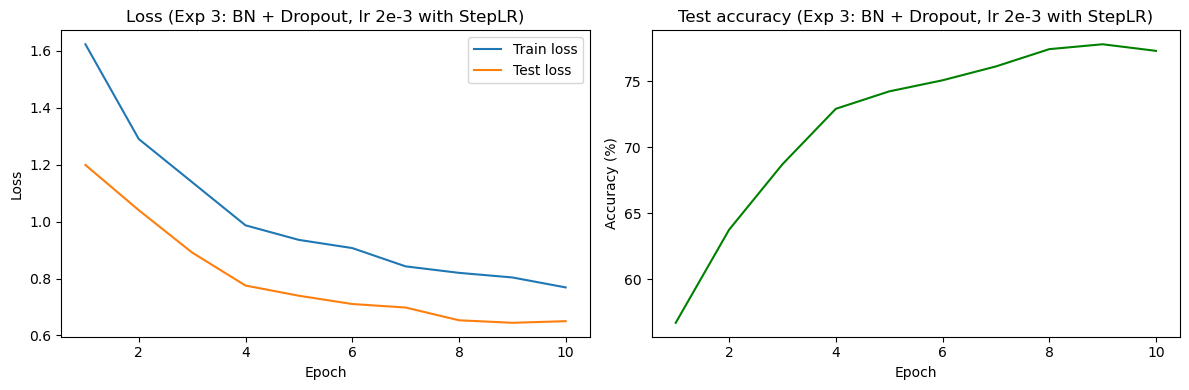

Final -> train loss 0.7687, test loss 0.6501, test acc 77.31%


In [11]:
### Task-5.3 Exp 3: BatchNorm + Dropout + StepLR
model3 = CNN2().to(device)
hist3 = fit(model3, epochs=10, lr=2e-3, scheduler_step=3)
plot_history(hist3, "(Exp 3: BN + Dropout, lr 2e-3 with StepLR)")
print(f"Final -> train loss {hist3['train_loss'][-1]:.4f}, "
      f"test loss {hist3['test_loss'][-1]:.4f}, test acc {hist3['test_acc'][-1]:.2f}%")

## Experiment 4 implementation
Run the following three cells in order. The definition cell does not start training.

In [ ]:
"""Experiment 4: CIFAR-10 CNN trained from scratch; no pretrained weights."""
import argparse
import json
import random
import time
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.datasets import CIFAR10

class ImprovedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        in_channels = 3
        for channels in (32, 64, 128):
            for _ in range(2):
                layers += [nn.Conv2d(in_channels, channels, 3, padding=1, bias=False),
                           nn.BatchNorm2d(channels), nn.ReLU(inplace=True)]
                in_channels = channels
            layers += [nn.MaxPool2d(2), nn.Dropout2d(0.1)]
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128*4*4, 256),
                                        nn.ReLU(inplace=True), nn.Dropout(0.3),
                                        nn.Linear(256, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


def run_experiment(data_path='./data_cifar', output_dir='./experiment4_results',
                   epochs=40, batch_size=128, seed=42):
    if epochs < 1 or batch_size < 1:
        raise ValueError('epochs and batch_size must be positive')
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(4)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if device.type == 'cuda':
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = True
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    print('Device:', device, flush=True)
    if device.type == 'cuda':
        print('GPU:', torch.cuda.get_device_name(), flush=True)
    else:
        print('CPU training may take substantially longer.', flush=True)
    dataset = CIFAR10(data_path, train=True, download=True)
    # Stratified 45,000 / 5,000 split of the official TRAINING data.
    labels = np.asarray(dataset.targets)
    rng = np.random.default_rng(seed)
    train_idx, val_idx = [], []
    for cls in range(10):
        idx = rng.permutation(np.flatnonzero(labels == cls))
        val_idx.extend(idx[:500])
        train_idx.extend(idx[500:])
    # Keep compact uint8 images on the selected device to reduce transfer overhead.
    images = torch.from_numpy(dataset.data.copy()).permute(0, 3, 1, 2).to(device)
    targets = torch.tensor(dataset.targets, device=device)
    train_idx = torch.tensor(train_idx, device=device)
    val_idx = torch.tensor(val_idx, device=device)
    mean = torch.tensor((0.4914, 0.4822, 0.4465), device=device).view(1,3,1,1)
    std = torch.tensor((0.2470, 0.2435, 0.2616), device=device).view(1,3,1,1)

    def preprocess(x, augment=False):
        x = x.float().div(255)
        if augment:
            # Per-image random crop with reflection padding of four pixels.
            x = F.pad(x, (4,4,4,4), mode='reflect')
            b = x.size(0)
            offsets = torch.randint(0, 9, (b,2), device=device)
            rows = offsets[:,0,None,None] + torch.arange(32, device=device)[None,:,None]
            cols = offsets[:,1,None,None] + torch.arange(32, device=device)[None,None,:]
            x = x.permute(0,2,3,1)[torch.arange(b,device=device)[:,None,None], rows, cols]
            x = x.permute(0,3,1,2)
            flip = torch.rand(b,1,1,1,device=device) < 0.5
            x = torch.where(flip, x.flip(-1), x)
        return ((x - mean) / std).contiguous()

    model = ImprovedCNN().to(device)
    print(model, flush=True)
    print('Train:', len(train_idx), 'Validation:', len(val_idx), flush=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)
    scaler = torch.amp.GradScaler('cuda', enabled=device.type == 'cuda')
    criterion = nn.CrossEntropyLoss()

    @torch.no_grad()
    def evaluate(xdata, ydata, indices):
        model.eval()
        loss_sum = torch.zeros((), device=device)
        correct = torch.zeros((), device=device)
        for idx in indices.split(batch_size):
            with torch.autocast(device_type=device.type, enabled=device.type == 'cuda'):
                logits = model(preprocess(xdata[idx]))
                loss = criterion(logits, ydata[idx])
            loss_sum += loss.float() * idx.numel()
            correct += (logits.argmax(1) == ydata[idx]).sum()
        return loss_sum.item()/len(indices), 100*correct.item()/len(indices)

    # The assignment explicitly requests test loss and test accuracy each epoch.
    # Log them for the report; checkpoint selection uses validation data only.
    testset = CIFAR10(data_path, train=False, download=True)
    test_images = torch.from_numpy(testset.data.copy()).permute(0,3,1,2).to(device)
    test_labels = torch.tensor(testset.targets, device=device)
    test_indices = torch.arange(len(testset), device=device)
    history = []
    best_accuracy, best_loss, best_epoch = -1.0, float('inf'), 0
    checkpoint = output/'best_model.pt'
    start = time.time()
    for epoch in range(1, epochs+1):
        tick = time.time()
        model.train()
        permutation = train_idx[torch.randperm(len(train_idx), device=device)]
        train_sum = torch.zeros((), device=device)
        correct = torch.zeros((), device=device)
        lr = optimizer.param_groups[0]['lr']
        for idx in permutation.split(batch_size):
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=device.type == 'cuda'):
                logits = model(preprocess(images[idx], augment=True))
                loss = criterion(logits, targets[idx])
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_sum += loss.detach().float() * idx.numel()
            correct += (logits.detach().argmax(1) == targets[idx]).sum()
        val_loss, val_accuracy = evaluate(images, targets, val_idx)
        epoch_test_loss, epoch_test_accuracy = evaluate(test_images, test_labels, test_indices)
        row = dict(epoch=epoch, train_loss=train_sum.item()/len(train_idx),
                   train_accuracy=100*correct.item()/len(train_idx),
                   validation_loss=val_loss, validation_accuracy=val_accuracy,
                   test_loss=epoch_test_loss, test_accuracy=epoch_test_accuracy,
                   learning_rate=lr, seconds=time.time()-tick)
        history.append(row)
        if val_accuracy > best_accuracy or (val_accuracy == best_accuracy and val_loss < best_loss):
            best_accuracy, best_loss, best_epoch = val_accuracy, val_loss, epoch
            torch.save({'model_state':model.state_dict(), 'epoch':epoch,
                        'validation_accuracy':val_accuracy, 'seed':seed}, checkpoint)
        scheduler.step()
        (output/'history.json').write_text(json.dumps(history, indent=2))
        print(f"Epoch {epoch:02d}/{epochs} train loss {row['train_loss']:.4f} | "
              f"val loss {val_loss:.4f} | val accuracy {val_accuracy:.2f}% | "
              f"test accuracy {epoch_test_accuracy:.2f}% | {row['seconds']:.1f}s", flush=True)
    # Reload the validation-selected checkpoint and report its test performance.
    saved = torch.load(checkpoint, map_location=device, weights_only=True)
    model.load_state_dict(saved['model_state'])
    test_loss, test_accuracy = evaluate(test_images, test_labels, test_indices)
    results = dict(best_epoch=best_epoch, best_validation_accuracy=best_accuracy,
                   selected_epoch_training_loss=history[best_epoch-1]['train_loss'],
                   final_epoch_training_loss=history[-1]['train_loss'],
                   test_loss=test_loss, test_accuracy=test_accuracy,
                   epochs=epochs, batch_size=batch_size, seed=seed,
                   train_samples=45000, validation_samples=5000, test_samples=10000,
                   torch_version=str(torch.__version__), device=str(device),
                   elapsed_seconds=time.time()-start)
    (output/'results.json').write_text(json.dumps(results, indent=2))
    print('FINAL RESULTS\n'+json.dumps(results, indent=2), flush=True)
    return history, results



In [ ]:
history4, results4 = run_experiment(
    data_path='./data_cifar', output_dir='./experiment4_results',
    epochs=40, batch_size=128, seed=42
)


Device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU
ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1,

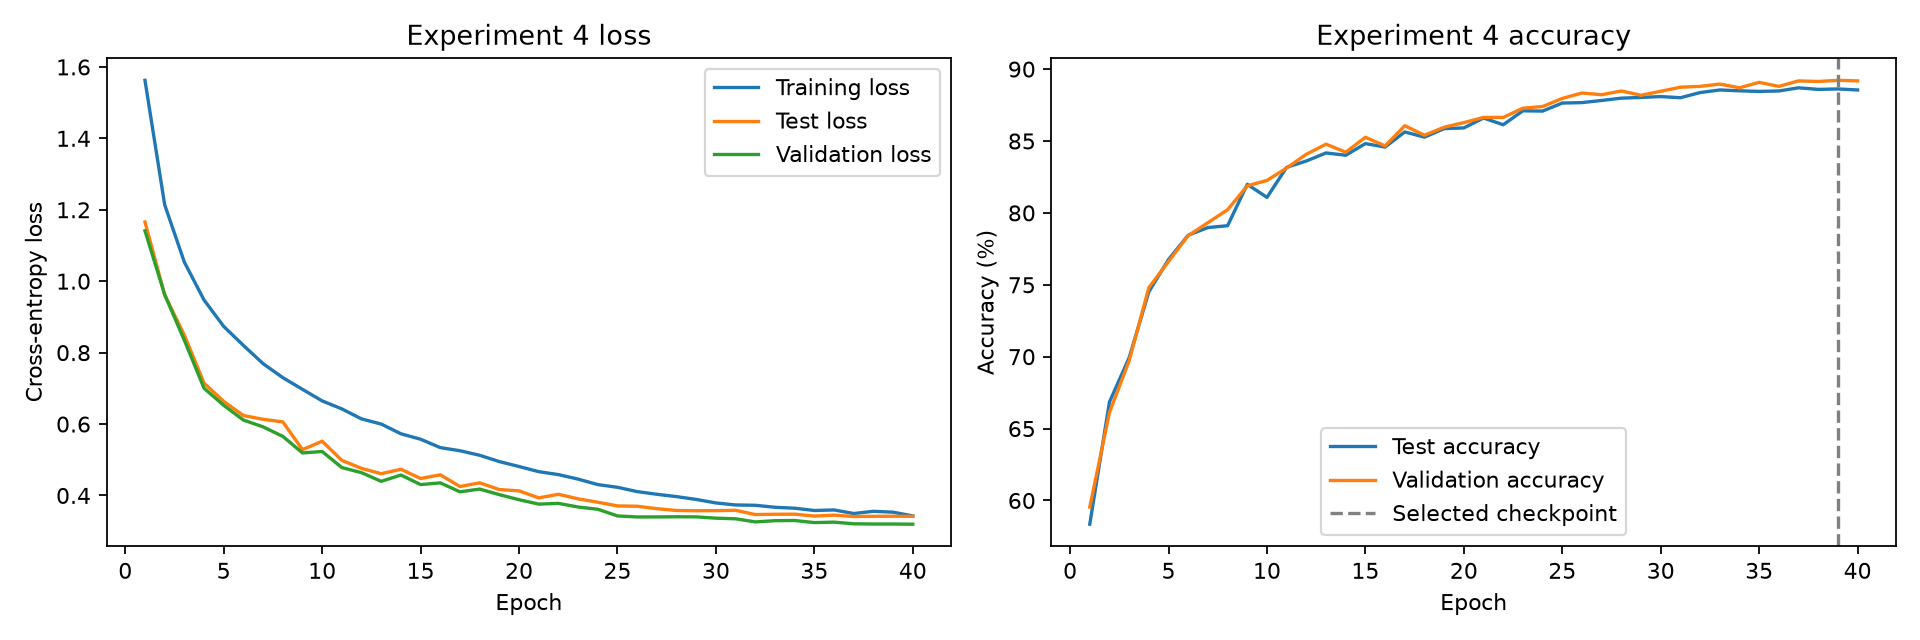

Selected epoch: 39
Test loss: 0.3418
Test accuracy: 88.62%
Difference from original final 77.31%: +11.31 percentage points


In [ ]:
import matplotlib.pyplot as plt
xs = [r['epoch'] for r in history4]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(xs, [r['train_loss'] for r in history4], label='Training loss')
ax[0].plot(xs, [r['test_loss'] for r in history4], label='Test loss')
ax[0].plot(xs, [r['validation_loss'] for r in history4], label='Validation loss')
ax[0].set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Experiment 4 loss')
ax[0].legend()
ax[1].plot(xs, [r['test_accuracy'] for r in history4], label='Test accuracy')
ax[1].plot(xs, [r['validation_accuracy'] for r in history4], label='Validation accuracy')
ax[1].axvline(results4['best_epoch'], linestyle='--', color='gray', label='Selected checkpoint')
ax[1].set(xlabel='Epoch', ylabel='Accuracy (%)', title='Experiment 4 accuracy')
ax[1].legend()
plt.tight_layout()
plt.savefig('experiment4_results/training_curves.png', dpi=160)
plt.show()
print(f"Selected epoch: {results4['best_epoch']}")
print(f"Test loss: {results4['test_loss']:.4f}")
print(f"Test accuracy: {results4['test_accuracy']:.2f}%")
print(f"Difference from original final 77.31%: {results4['test_accuracy'] - 77.31:+.2f} percentage points")


References for implementation: [AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW) and [cosine learning-rate schedule](https://docs.pytorch.org/docs/main/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html).

## Task 6 Save source code and prepare submission
Save this notebook after training so the actual results and figures remain visible. Upload the saved notebook to your GitHub repository and enter its URL in the report.

Group GitHub repository: https://github.com/mohaiyaaldossary/ARTI502-Assignment-2

The Assignment 2 files are ready to upload to the group repository. This notebook does not assert that the new files have already been uploaded.

For the report, capture the dataset loading output, CNN definitions, training and test functions, image tensor sizes, image visualization, augmentation code, experiment training code, and loss/accuracy plots. Use only the measured results printed by the completed run.

Validation status: notebook structure and Python syntax checked; the new model passed a GPU forward/backward check. The new experiment completed 40 epochs on the NVIDIA RTX 3060 Laptop GPU. Selected-model test accuracy: 88.62%; test loss: 0.3418. Original saved results belong only to Experiments 1–3.
